In [1]:
!pip install nbformat

In [2]:
!pip install plotly

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import os

In [4]:
data_path = r"E:\VirtualWorks-Intership\task4-geospatial-analysis\data\Sample - Superstore.csv"
output_path = r"E:\VirtualWorks-Intership\task4-geospatial-analysis\output"

In [5]:
df = pd.read_csv(data_path, encoding="latin1")
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())


Dataset loaded successfully!
Dataset shape: (9994, 21)

First five rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Regi

In [6]:
state_data = df.groupby("State").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

state_data["Sales_per_Order"] = (
    state_data["Sales"] / state_data["Orders"]
)

state_data = state_data.sort_values(
    "Sales", ascending=False
)

print("\nTop 10 States by Sales:")
print(state_data.head(10).to_string(index=False))


Top 10 States by Sales:
       State       Sales      Profit  Orders  Sales_per_Order
  California 457687.6315  76381.3871    1021       448.273880
    New York 310876.2710  74038.5486     562       553.160625
       Texas 170188.0458 -25729.3563     487       349.462106
  Washington 138641.2700  33402.6517     256       541.567461
Pennsylvania 116511.9140 -15559.9603     288       404.555257
     Florida  89473.7080  -3399.3017     200       447.368540
    Illinois  80166.1010 -12607.8870     276       290.456888
        Ohio  78258.1360 -16971.3766     236       331.602271
    Michigan  76269.6140  24463.1876     117       651.877043
    Virginia  70636.7200  18597.9504     115       614.232348


In [7]:
state_codes = {
    "Alabama": "AL",
    "Arizona": "AZ",
    "Arkansas": "AR",
    "California": "CA",
    "Colorado": "CO",
    "Connecticut": "CT",
    "Delaware": "DE",
    "District of Columbia": "DC",
    "Florida": "FL",
    "Georgia": "GA",
    "Idaho": "ID",
    "Illinois": "IL",
    "Indiana": "IN",
    "Iowa": "IA",
    "Kansas": "KS",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maine": "ME",
    "Maryland": "MD",
    "Massachusetts": "MA",
    "Michigan": "MI",
    "Minnesota": "MN",
    "Mississippi": "MS",
    "Missouri": "MO",
    "Montana": "MT",
    "Nebraska": "NE",
    "Nevada": "NV",
    "New Hampshire": "NH",
    "New Jersey": "NJ",
    "New Mexico": "NM",
    "New York": "NY",
    "North Carolina": "NC",
    "North Dakota": "ND",
    "Ohio": "OH",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "Pennsylvania": "PA",
    "Rhode Island": "RI",
    "South Carolina": "SC",
    "South Dakota": "SD",
    "Tennessee": "TN",
    "Texas": "TX",
    "Utah": "UT",
    "Vermont": "VT",
    "Virginia": "VA",
    "Washington": "WA",
    "West Virginia": "WV",
    "Wisconsin": "WI",
    "Wyoming": "WY",
    "Alaska": "AK",
    "Hawaii": "HI"
}

state_data["Code"] = state_data["State"].map(state_codes)

In [8]:
map_data = state_data.dropna(subset=["Code"])

fig = px.choropleth(
    map_data,
    locations="Code",
    locationmode="USA-states",
    color="Sales",
    hover_name="State",
    hover_data=["Profit", "Orders"],
    scope="usa",
    color_continuous_scale="Blues",
    title="US State Sales Analysis"
)

fig.update_layout(
    title_x=0.5,
    margin={"r": 10, "t": 60, "l": 10, "b": 10}
)

fig.show()

fig.write_html(
    os.path.join(output_path, "sales_map.html")
)


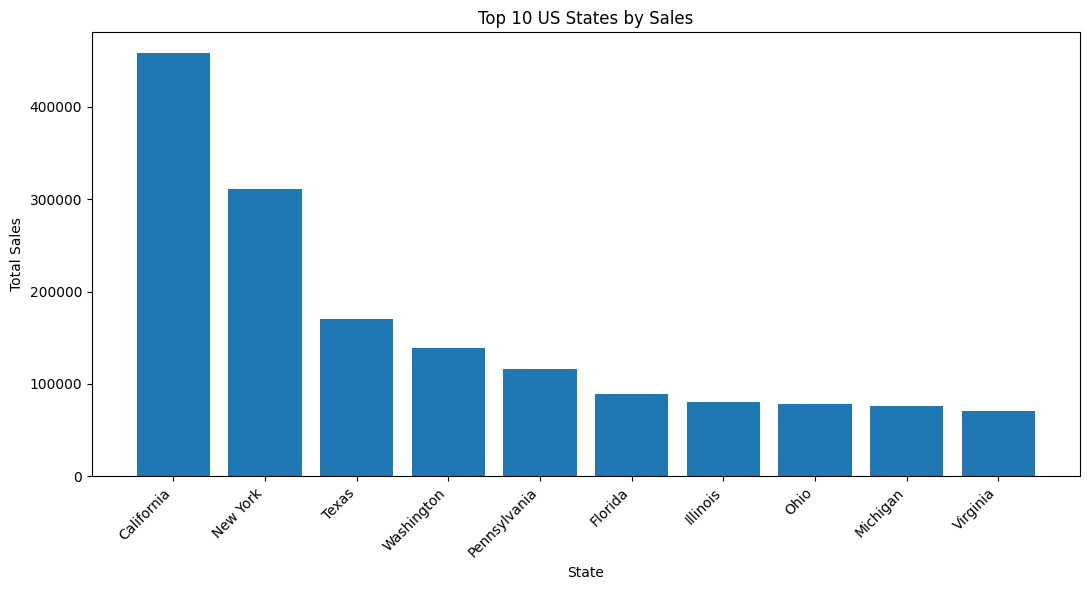

In [9]:
top_states = state_data.head(10)

plt.figure(figsize=(11, 6))
plt.bar(top_states["State"], top_states["Sales"])
plt.title("Top 10 US States by Sales")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(output_path, "top_states.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [10]:
city_data = df.groupby("City").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

city_data = city_data.sort_values(
    "Sales", ascending=False
)

print("\nTop 10 Cities by Sales:")
print(city_data.head(10).to_string(index=False))

city_data.head(10).to_csv(
    os.path.join(output_path, "top_cities.csv"),
    index=False
)



Top 10 Cities by Sales:
         City       Sales      Profit  Orders
New York City 256368.1610  62036.9837     450
  Los Angeles 175851.3410  30440.7579     384
      Seattle 119540.7420  29156.0967     212
San Francisco 112669.0920  17507.3854     265
 Philadelphia 109077.0130 -13837.7674     265
      Houston  64504.7604 -10153.5485     188
      Chicago  48539.5410  -6654.5688     171
    San Diego  47521.0290   6377.1960      88
 Jacksonville  44713.1830  -2323.8350      61
  Springfield  43054.3420   6200.6974      73


In [11]:
order_median = state_data["Orders"].median()
sales_per_order_median = state_data["Sales_per_Order"].median()

candidates = state_data[
    (state_data["Orders"] < order_median) &
    (state_data["Sales_per_Order"] > sales_per_order_median) &
    (state_data["Profit"] > 0)
].copy()

print("\nPreliminary Expansion Candidates:")
if candidates.empty:
    print("No states met all the selected criteria.")
else:
    print(
        candidates[
            ["State", "Sales", "Profit", "Orders", "Sales_per_Order"]
        ].to_string(index=False)
    )

candidates.to_csv(
    os.path.join(output_path, "expansion_candidates.csv"),
    index=False
)


Preliminary Expansion Candidates:
               State     Sales    Profit  Orders  Sales_per_Order
        Rhode Island 22627.956 7285.6293      25       905.118240
            Missouri 22205.150 6436.2105      30       740.171667
            Oklahoma 19683.390 4853.9560      34       578.923235
             Alabama 19510.640 5786.8253      34       573.842353
              Nevada 16729.102 3316.7659      23       727.352261
             Vermont  8929.370 2244.9783       6      1488.228333
             Montana  5589.352 1833.3285       8       698.669000
District of Columbia  2865.020 1059.5893       4       716.255000
             Wyoming  1603.136  100.1960       1      1603.136000
       West Virginia  1209.824  185.9216       2       604.912000
        North Dakota   919.910  230.1497       2       459.955000


In [12]:
state_data.to_csv(
    os.path.join(output_path, "state_sales_analysis.csv"),
    index=False
)

In [13]:
print("\nKEY FINDINGS")

print(
    "Highest-sales state:",
    state_data.loc[state_data["Sales"].idxmax(), "State"]
)

print(
    "Most profitable state:",
    state_data.loc[state_data["Profit"].idxmax(), "State"]
)

print(
    "Lowest-sales state:",
    state_data.loc[state_data["Sales"].idxmin(), "State"]
)

print("\nAnalysis completed successfully!")
print("Output files saved to:", output_path)


KEY FINDINGS
Highest-sales state: California
Most profitable state: California
Lowest-sales state: North Dakota

Analysis completed successfully!
Output files saved to: E:\VirtualWorks-Intership\task4-geospatial-analysis\output
